In [1]:
pip install numpy tensorflow matplotlib

Note: you may need to restart the kernel to use updated packages.


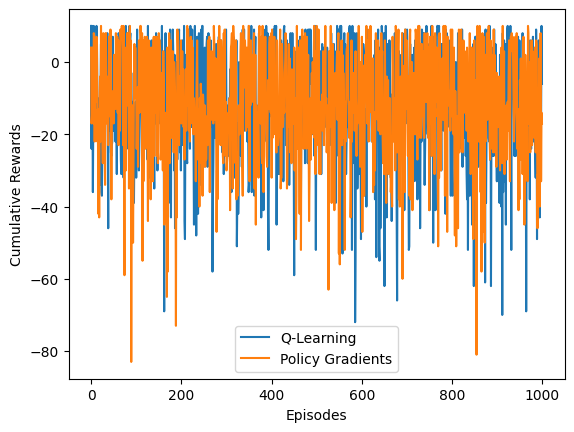

In [20]:
import numpy as np
import tensorflow as tf
import matplotlib.pyplot as plt

# --- Shared Environment Setup ---
grid_size = 5
n_states = grid_size * grid_size
n_actions = 4 # Actions: up, down, left, right

# Reward matrix for the grid environment
rewards = np.full((n_states,), -1.0) # -1 for every state
rewards[24] = 10.0 # Goal state (state index 24 is (4,4) in 0-indexed grid)
rewards[12] = -10.0 # Pitfall state (state index 12 is (2,2) in 0-indexed grid)

# --- Q-Learning Implementation ---

# Initialize the Q-table with zeros
Q_table = np.zeros((n_states, n_actions))

alpha = 0.1 # Learning rate
gamma = 0.9 # Discount factor for future rewards
epsilon = 0.1 # Exploration rate for epsilon-greedy policy

def epsilon_greedy_action(Q_table, state, epsilon):
    if np.random.uniform(0, 1) < epsilon:
        return np.random.randint(0, n_actions) # Explore: random action
    else:
        return np.argmax(Q_table[state]) # Exploit: action with highest Q-value

rewards_q_learning = [] # List to store cumulative reward per episode

for episode in range(1000):
    state = np.random.randint(0, n_states) # Start in a random state
    done = False
    episode_reward_sum = 0 # Track reward for current episode
    
    # Simulate an episode
    while not done:
        action = epsilon_greedy_action(Q_table, state, epsilon)
        
        # Simulated next state and reward (simplified, not true grid transition)
        next_state = np.random.randint(0, n_states)
        reward = rewards[next_state]
        episode_reward_sum += reward

        # Update Q-value using Bellman equation
        Q_table[state, action] = Q_table[state, action] + alpha * (reward + gamma * np.max(Q_table[next_state]) - Q_table[state, action])

        state = next_state
        if next_state in {24, 12}: # Terminal states
            done = True
            
    rewards_q_learning.append(episode_reward_sum)

# --- Policy Gradients (REINFORCE) Implementation ---

# Define the policy network
model = tf.keras.Sequential([
    tf.keras.layers.Dense(24, activation='relu', input_shape=(n_states,)),
    tf.keras.layers.Dense(n_actions, activation='softmax') # Output action probabilities
])

# Optimizer for policy network updates
optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)

def get_action(state):
    # Ensure state is a numpy int before passing to tf.one_hot
    state = int(state)
    state_input = tf.one_hot(state, n_states, dtype=tf.float32) # One-hot encoding for state
    action_probs = model(state_input[tf.newaxis, :])
    return np.random.choice(n_actions, p=action_probs.numpy()[0])

def compute_cumulative_rewards(rewards, gamma=0.9):
    cumulative_rewards = np.zeros_like(rewards, dtype=np.float32)
    running_add = 0
    for t in reversed(range(len(rewards))):
        running_add = running_add * gamma + rewards[t]
        cumulative_rewards[t] = running_add
    # Standardize rewards for better training stability (optional, but good practice)
    if len(cumulative_rewards) > 1:
        cumulative_rewards = (cumulative_rewards - np.mean(cumulative_rewards)) / (np.std(cumulative_rewards) + 1e-9)
    return cumulative_rewards

def update_policy(states, actions, rewards):
    # Ensure inputs are numpy arrays of correct type
    states = np.array(states, dtype=np.int32)
    actions = np.array(actions, dtype=np.int32)
    rewards = np.array(rewards, dtype=np.float32)
    
    cumulative_rewards = compute_cumulative_rewards(rewards)

    with tf.GradientTape() as tape:
        state_inputs = tf.one_hot(states, n_states, dtype=tf.float32) # Convert states to one-hot encoding
        action_probs = model(state_inputs)
        action_masks = tf.one_hot(actions, n_actions, dtype=tf.float32) # Mask for selected actions
        
        # Select the probability of the action taken
        selected_action_probs = tf.reduce_sum(action_masks * action_probs, axis=1)
        # Calculate the log probability of the action taken
        log_probs = tf.math.log(selected_action_probs + 1e-9) # Add epsilon for stability

        # Policy loss is the negative log-probability of the action times the cumulative reward
        loss = -tf.reduce_mean(log_probs * cumulative_rewards)

    # Apply gradients to update the policy network
    grads = tape.gradient(loss, model.trainable_variables)
    optimizer.apply_gradients(zip(grads, model.trainable_variables))

rewards_policy_gradients = [] # List to store cumulative reward per episode

# Simulation loop
for episode in range(1000):
    episode_states = []
    episode_actions = []
    episode_rewards_list = []
    episode_reward_sum = 0
    
    state = np.random.randint(0, n_states) # Start in a random state
    done = False
    
    while not done:
        action = get_action(state)
        next_state = np.random.randint(0, n_states) # Simulated next state
        reward = rewards[next_state]

        # Store the state-action-reward trajectory
        episode_states.append(state)
        episode_actions.append(action)
        episode_rewards_list.append(reward)
        episode_reward_sum += reward

        state = next_state
        if next_state in {24, 12}:
            done = True

    # Policy Update after episode end (Monte Carlo Policy Gradient)
    if episode_states:
        update_policy(episode_states, episode_actions, episode_rewards_list)

    # Store total episode reward for plotting
    rewards_policy_gradients.append(episode_reward_sum)

# Visualize rewards over episodes
plt.plot(rewards_q_learning, label='Q-Learning')
plt.plot(rewards_policy_gradients, label='Policy Gradients')
plt.xlabel('Episodes')
plt.ylabel('Cumulative Rewards')
plt.legend()
plt.show()